In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

path = "../data/realized_variance_forex_20261030/realized_variance_forex_20261030.csv"   # futures: replace "forex" with "futures" in both places
df = pd.read_csv(path, parse_dates=["date"]).sort_values(["symbol", "date"])
df.head()

,date,symbol,asset_type,open_price,close_price,high_price,low_price,pr,gkr,rr5,...,medrv1,medrv5,medrv5_ss,minrv1,minrv5,minrv5_ss,rk,rq1,rq5,rq5_ss
0,2009-09-25,AUDUSD,forex,0.8649,0.8652,0.8714,0.8616,0.000046,0.000064,0.000082,...,0.000094,0.000077,0.000091,0.000099,0.000071,0.000091,0.000103,1.622110e-08,2.129184e-08,2.004485e-08
1,2009-09-28,AUDUSD,forex,0.8596,0.8750,0.8756,0.8592,0.000128,0.000056,0.000063,...,0.000070,0.000073,0.000077,0.000069,0.000072,0.000079,0.000087,1.376545e-08,1.029935e-08,1.092435e-08
2,2009-09-29,AUDUSD,forex,0.8750,0.8792,0.8804,0.8676,0.000077,0.000099,0.000079,...,0.000083,0.000084,0.000072,0.000083,0.000082,0.000067,0.000098,1.388606e-07,1.775986e-08,2.274534e-08
3,2009-09-30,AUDUSD,forex,0.8791,0.8815,0.8859,0.8769,0.000037,0.000049,0.000072,...,0.000082,0.000065,0.000066,0.000081,0.000063,0.000064,0.000083,1.609287e-08,1.124176e-08,9.594611e-09
4,2009-10-01,AUDUSD,forex,0.8815,0.8697,0.8833,0.8672,0.000123,0.000100,0.000079,...,0.000098,0.000075,0.000081,0.000096,0.000074,0.000080,0.000100,2.081140e-08,1.649494e-08,1.577812e-08


In [2]:
print(df.shape)
print(df.groupby("symbol")["date"].agg(["count", "min", "max"]))

df["gap"] = df.groupby("symbol")["date"].diff().dt.days
df[df["gap"] > 5][["date", "symbol", "gap"]]

(22178, 32)
        count        min        max
symbol                             
AUDUSD   4436 2009-09-25 2026-10-30
EURUSD   4436 2009-09-25 2026-10-30
GBPUSD   4437 2009-09-25 2026-10-30
USDCAD   4435 2009-09-25 2026-10-30
USDJPY   4434 2009-09-28 2026-10-30


,date,symbol,gap


In [3]:
print(df.isna().sum().sum())
print((df["rv5"] <= 0).sum())
print((df[["open_price", "close_price", "high_price", "low_price"]] <= 0).sum())

5
0
open_price     0
close_price    0
high_price     0
low_price      0
dtype: int64


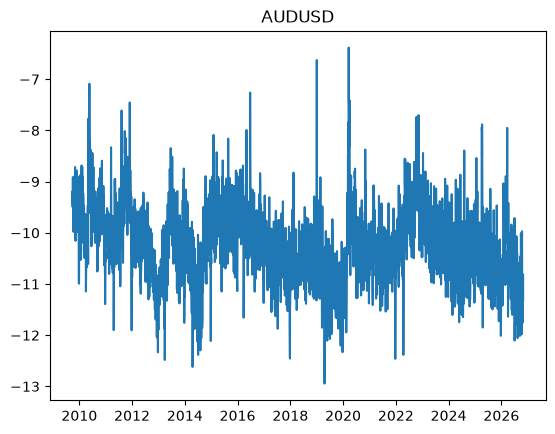

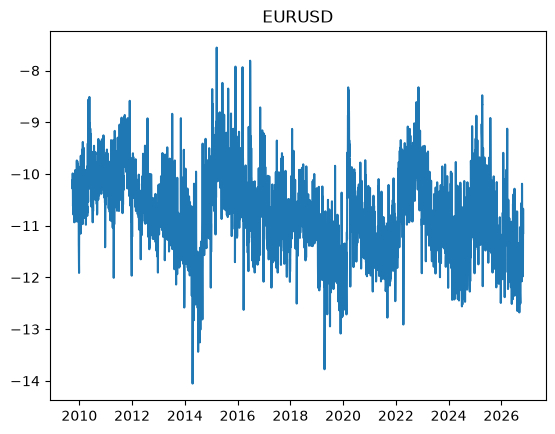

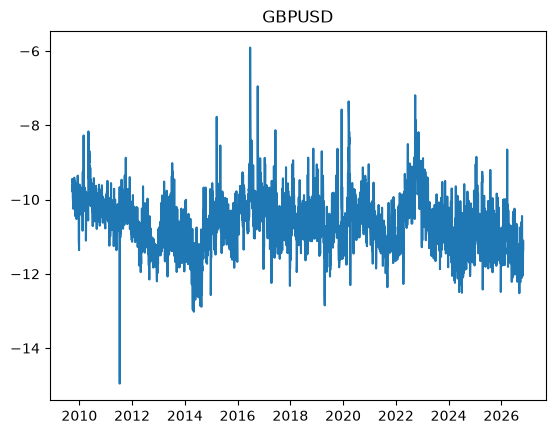

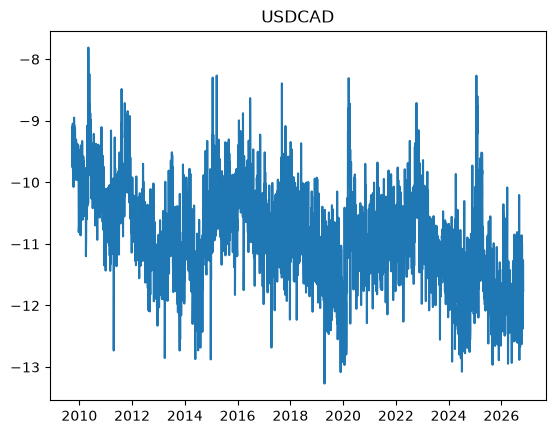

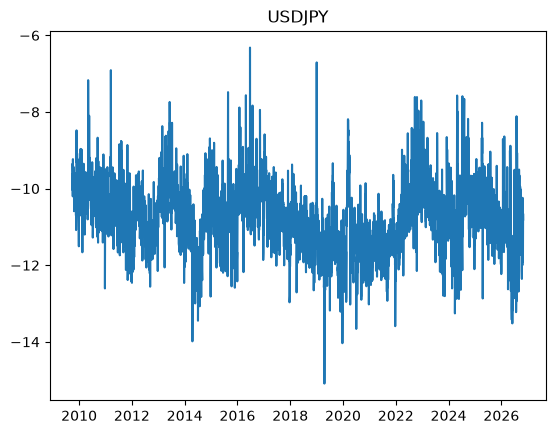

In [4]:
df["log_rv5"] = np.log(df["rv5"])
for s, g in df.groupby("symbol"):
    plt.figure()
    plt.plot(g["date"], g["log_rv5"])
    plt.title(s)

In [5]:
df["rel"] = df["rv5"] / df.groupby("symbol")["rv5"].transform("median")
df.sort_values("rel", ascending=False).groupby("symbol").head(3)[["date", "symbol", "rel", "rv5"]]

,date,symbol,rel,rv5
10621,2016-06-23,GBPUSD,120.476822,0.002715
19490,2016-06-23,USDJPY,87.633765,0.001801
20145,2019-01-02,USDJPY,59.522047,0.001223
10622,2016-06-24,GBPUSD,56.154732,0.001265
2717,2020-03-19,AUDUSD,49.866573,0.001693
18124,2011-03-16,USDJPY,48.597388,0.000999
10696,2016-10-06,GBPUSD,42.517173,0.000958
2403,2019-01-02,AUDUSD,39.108010,0.001328
2716,2020-03-18,AUDUSD,27.761719,0.000943
5855,2015-03-18,EURUSD,26.041122,0.000523


In [8]:
for k in [1, 5, 22]:
    print(k, df.groupby("symbol")["log_rv5"].apply(lambda s: s.autocorr(lag=k)).round(2).to_dict())

1 {'AUDUSD': 0.72, 'EURUSD': 0.73, 'GBPUSD': 0.72, 'USDCAD': 0.75, 'USDJPY': 0.7}
5 {'AUDUSD': 0.62, 'EURUSD': 0.66, 'GBPUSD': 0.64, 'USDCAD': 0.7, 'USDJPY': 0.54}
22 {'AUDUSD': 0.42, 'EURUSD': 0.5, 'GBPUSD': 0.41, 'USDCAD': 0.58, 'USDJPY': 0.36}


In [9]:
df.nsmallest(10, "rv5")[["date", "symbol", "rv5"]]

,date,symbol,rv5
20222,2019-04-19,USDJPY,2.796098e-07
9339,2011-07-14,GBPUSD,3.198960e-07
5620,2014-04-18,EURUSD,7.883573e-07
20399,2019-12-24,USDJPY,8.023110e-07
18927,2014-04-18,USDJPY,8.424170e-07
6916,2019-04-19,EURUSD,1.039815e-06
20535,2020-07-03,USDJPY,1.165282e-06
20918,2021-12-24,USDJPY,1.251664e-06
22069,2026-06-02,USDJPY,1.345634e-06
18982,2014-07-04,USDJPY,1.443222e-06


In [10]:
df["range"] = (df["high_price"] - df["low_price"]) / df["close_price"]
sus = df[(df["range"] > 0.15) & (df["rel"] < 10)]   # for forex use 0.05
print(sus.groupby("symbol").size())
sus[["date", "symbol", "range", "rel"]]

symbol
GBPUSD    1
dtype: int64


,date,symbol,range,rel
9571,2012-06-04,GBPUSD,0.502078,0.667557


In [11]:
df[df["gap"] > 5][["date", "symbol", "gap"]]            # missing stretches (futures has uneven row counts)
df[df["date"] == "2023-01-24"][["symbol", "rel", "range"]]   # was that date strange across assets?

,symbol,rel,range
3458,AUDUSD,2.653054,0.016193
7894,EURUSD,1.255183,0.006239
12331,GBPUSD,1.973398,0.012170
16766,USDCAD,1.253745,0.005017
21200,USDJPY,2.491196,0.010623
